# 实验 02 · 从方环到填充：模 2 同调

**对应：第三章、计算拓扑、持续同调导读。** 输入为单位正方形的四个点，距离采用欧氏距离。当 $d(x_i,x_j)\le r$ 时加入边；三条边齐全时加入三角形。

理论：$\beta_1=n_1-\operatorname{rank}_{\mathbb F_2}D_1-\operatorname{rank}_{\mathbb F_2}D_2$，证明见第三章。可运行内容：构造边界矩阵、模 2 消元、核验已知答案、绘制复形与 Betti 曲线。

仅构建二维骨架，足以计算 $H_0,H_1$，不能用它代替完整 Rips 复形的 $H_2$。本实验没有实现一般持续配对算法。依赖 NumPy、Matplotlib，无外部数据和网络请求。


In [1]:
from itertools import combinations
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

def rank_f2(matrix):
    """Exact row reduction over F_2, including empty matrices."""
    a = np.asarray(matrix, dtype=np.uint8).copy() % 2
    rows, columns = a.shape
    rank = 0
    for column in range(columns):
        pivot = next((i for i in range(rank, rows) if a[i, column]), None)
        if pivot is None:
            continue
        a[[rank, pivot]] = a[[pivot, rank]]
        for i in range(rows):
            if i != rank and a[i, column]:
                a[i] ^= a[rank]
        rank += 1
        if rank == rows:
            break
    return rank

def boundary_matrix(lower, upper):
    matrix = np.zeros((len(lower), len(upper)), dtype=np.uint8)
    row = {simplex: i for i, simplex in enumerate(lower)}
    for j, simplex in enumerate(upper):
        for face in combinations(simplex, len(simplex) - 1):
            matrix[row[face], j] = 1
    return matrix

def betti_h01(vertices, edges, triangles):
    d1 = boundary_matrix(vertices, edges)
    d2 = boundary_matrix(edges, triangles)
    assert np.all((d1.astype(np.int64) @ d2.astype(np.int64)) % 2 == 0)
    return (len(vertices) - rank_f2(d1),
            len(edges) - rank_f2(d1) - rank_f2(d2))


## 先用手算例子检验代码

空心三角形的 $(\beta_0,\beta_1)=(1,1)$；填实三角形为 $(1,0)$。同一张无符号边界矩阵在实数域上的秩与模 2 秩不同，不能混用。


In [2]:
vertices3 = [(0,), (1,), (2,)]
edges3 = [(0, 1), (0, 2), (1, 2)]
assert betti_h01(vertices3, edges3, []) == (1, 1)
assert betti_h01(vertices3, edges3, [(0, 1, 2)]) == (1, 0)
d1_triangle = boundary_matrix(vertices3, edges3)
assert rank_f2(d1_triangle) == 2
assert np.linalg.matrix_rank(d1_triangle.astype(float)) == 3
assert rank_f2(np.zeros((4, 0), dtype=np.uint8)) == 0
print('Hollow triangle:', betti_h01(vertices3, edges3, []))
print('Filled triangle:', betti_h01(vertices3, edges3, [(0, 1, 2)]))
print('Boundary rank over F2 / R:', rank_f2(d1_triangle),
      np.linalg.matrix_rank(d1_triangle.astype(float)))


Hollow triangle: (1, 1)
Filled triangle: (1, 0)
Boundary rank over F2 / R: 2 3


In [3]:
points = np.array([[0., 0.], [1., 0.], [1., 1.], [0., 1.]])

def rips_2_skeleton(points, radius):
    if radius < 0:
        raise ValueError('radius must be nonnegative')
    vertices = [(i,) for i in range(len(points))]
    edges = [pair for pair in combinations(range(len(points)), 2)
             if np.linalg.norm(points[pair[0]] - points[pair[1]]) <= radius]
    edge_set = set(edges)
    triangles = [triple for triple in combinations(range(len(points)), 3)
                 if all(pair in edge_set for pair in combinations(triple, 2))]
    return vertices, edges, triangles

samples = [(0.9, (4, 0)), (1.0, (1, 1)), (math.sqrt(2), (1, 0))]
for radius, expected in samples:
    complex_ = rips_2_skeleton(points, radius)
    actual = betti_h01(*complex_)
    assert actual == expected
    print(f'r={radius:.6f}: vertices/edges/triangles={tuple(map(len, complex_))}, beta={actual}')

# Boundary checks use thresholds away from floating-point rounding ambiguity.
assert betti_h01(*rips_2_skeleton(points, 1 - 1e-8)) == (4, 0)
assert betti_h01(*rips_2_skeleton(points, math.sqrt(2) - 1e-8)) == (1, 1)
assert betti_h01(*rips_2_skeleton(2 * points, 2.1)) == (1, 1)


r=0.900000: vertices/edges/triangles=(4, 0, 0), beta=(4, 0)
r=1.000000: vertices/edges/triangles=(4, 4, 0), beta=(1, 1)
r=1.414214: vertices/edges/triangles=(4, 6, 4), beta=(1, 0)


## 可视化三个尺度

第三幅图叠加四个三角形，只是二维骨架的平面投影；不意味着它们的抽象拓扑等于一个平面正方形。这里只解释 $H_0,H_1$。完整四点 Rips 复形在该尺度还含有一个三维单形。


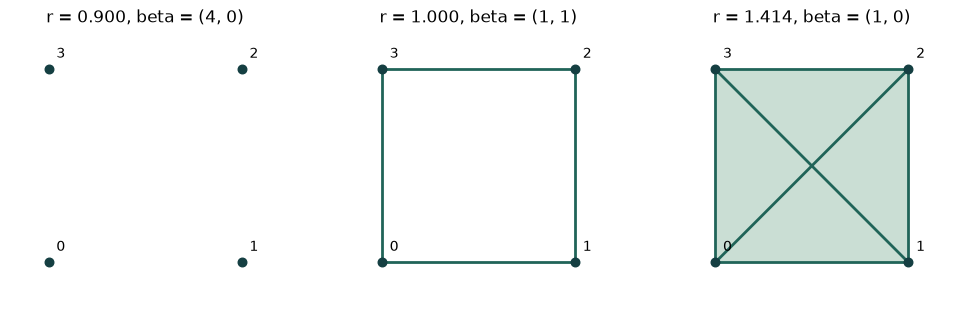

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3), constrained_layout=True)
for ax, (radius, _) in zip(axes, samples):
    vertices, edges, triangles = rips_2_skeleton(points, radius)
    for triangle in triangles:
        ax.add_patch(Polygon(points[list(triangle)], facecolor='#92bda6',
                             edgecolor='none', alpha=0.28))
    for edge in edges:
        segment = points[list(edge)]
        ax.plot(segment[:, 0], segment[:, 1], color='#206458', linewidth=2)
    ax.scatter(points[:, 0], points[:, 1], c='#153f42', s=38, zorder=3)
    for i, (x, y) in enumerate(points):
        ax.text(x + 0.04, y + 0.06, str(i))
    ax.set_title(f'r = {radius:.3f}, beta = {betti_h01(vertices, edges, triangles)}')
    ax.set(xlim=(-.2, 1.2), ylim=(-.2, 1.2), aspect='equal')
    ax.set_axis_off()
plt.show()


## Betti 曲线不是一般持续条形码

下面显示每个尺度上的维数。这个四点例子只有一个一维类，结合第三章的包含关系分析，可确定其区间为 $[1,\sqrt2)$。一般情况下，需要诱导映射或持续矩阵约化来匹配类，单凭 Betti 曲线不能恢复条形码。


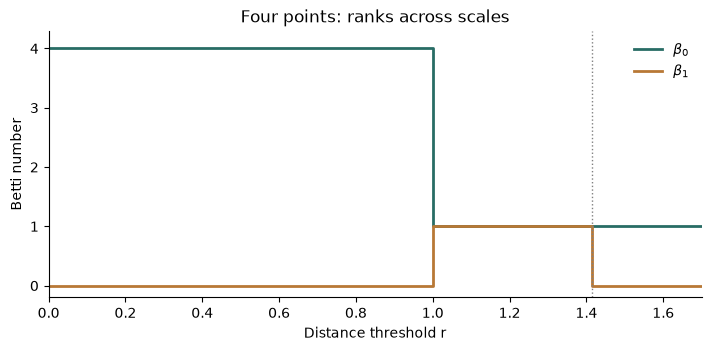

In [5]:
radii = np.array([0., 1., math.sqrt(2), 1.7])
betti_values = np.array([betti_h01(*rips_2_skeleton(points, r)) for r in radii])
fig, ax = plt.subplots(figsize=(7, 3.4), constrained_layout=True)
for dimension, color in [(0, '#286c65'), (1, '#b87835')]:
    ax.step(radii, betti_values[:, dimension], where='post', color=color,
            label=fr'$\beta_{dimension}$', linewidth=2)
ax.axvline(math.sqrt(2), color='gray', linestyle=':', linewidth=1)
ax.set(xlabel='Distance threshold r', ylabel='Betti number',
       title='Four points: ranks across scales', xlim=(0, 1.7), ylim=(-.2, 4.3),
       yticks=range(5))
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.show()


## 练习与适用范围

1. 把坐标乘以 2，先预测、再核验出生和死亡尺度变为 $2$ 与 $2\sqrt2$。
2. 把正方形改为宽 2、高 1 的矩形，写出各临界距离。
3. 只加对角线、不加三角面时，第一 Betti 数如何变化？先用第三章秩公式手算。

本实现枚举最多 $\binom n3$ 个三角形，仅供小数据教学。浮点距离的临界比较可能受舍入影响；实际噪声数据应明确阈值与容差策略。本例保留 `<=` 的数学约定，没有隐式增加阈值。

参考：Edelsbrunner and Harer, *Computational Topology: An Introduction*, 2010。说明、代码与生成图形为本项目原创。
